In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
from pathlib import Path
from IPython.display import display

pd.set_option('display.max_columns', 30)
figure_dir = Path('figures')
figure_dir.mkdir(exist_ok=True)

df = pd.read_csv('modelling.csv', keep_default_na=False, na_values=[''])
df['Date'] = pd.to_datetime(df['Date'], errors='raise')
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,Day,WeekOfYear
0,1097,2,2013-01-01,5961,1405,1,0,1,1,1,1,720.0,3.0,2002.0,0,0.0,0.0,None,2013,1,1,1
1,85,2,2013-01-01,4220,619,1,0,1,1,1,0,1870.0,10.0,2011.0,0,0.0,0.0,None,2013,1,1,1
2,259,2,2013-01-01,6851,1444,1,0,1,1,1,1,210.0,0.0,0.0,0,0.0,0.0,None,2013,1,1,1
3,262,2,2013-01-01,17267,2875,1,0,1,1,1,0,1180.0,5.0,2013.0,0,0.0,0.0,None,2013,1,1,1
4,335,2,2013-01-01,2401,482,1,0,1,1,1,0,90.0,0.0,0.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct",2013,1,1,1


,size,mean,median
SchoolHoliday,,,
0,140692,10334.513626,9626.0
1,34308,10715.727993,9940.0


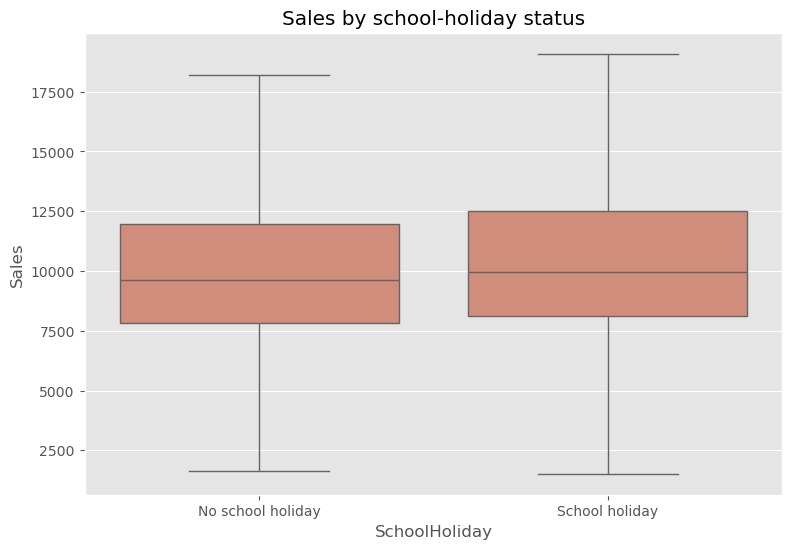

In [3]:
plt.figure(figsize=(9,6))
sns.boxplot(data=df,x='SchoolHoliday',y='Sales',order=[0,1],showfliers=False,color='#df856d')
plt.xticks([0,1],['No school holiday','School holiday'])
plt.title('Sales by school-holiday status')
plt.xlabel('SchoolHoliday'); plt.ylabel('Sales')
display(df.groupby('SchoolHoliday').Sales.agg(['size','mean','median']))

,size,mean,median
StateHoliday,,,
0,174562,10406.252203,9686.0
1,295,11432.386441,10846.0
2,93,12322.000000,11559.0
3,50,11277.800000,10538.0


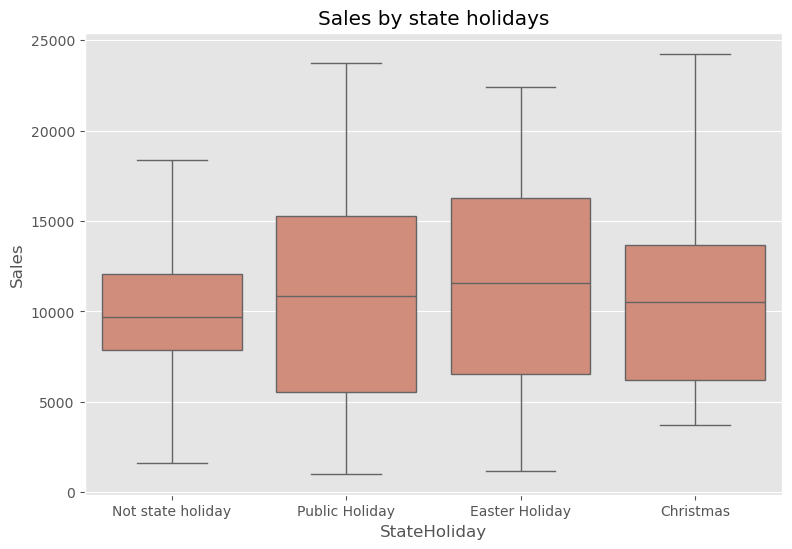

<Figure size 900x600 with 0 Axes>

In [4]:
plt.figure(figsize=(9,6))
order = ['0','1','2','3']
sns.boxplot(data=df,x='StateHoliday',y='Sales',order=order,showfliers=False,color='#df856d')
plt.xticks([0,1,2,3],['Not state holiday','Public Holiday', 'Easter Holiday', 'Christmas'])
plt.title('Sales by state holidays')
plt.xlabel('StateHoliday'); plt.ylabel('Sales')
plt.figure(figsize=(9,6))
display(df.groupby('StateHoliday')['Sales'].agg(['size', 'mean', 'median']))

,size,mean,median
StateHoliday,,,
0,174562,10406.252203,9686.0
1,295,11432.386441,10846.0
2,93,12322.000000,11559.0
3,50,11277.800000,10538.0


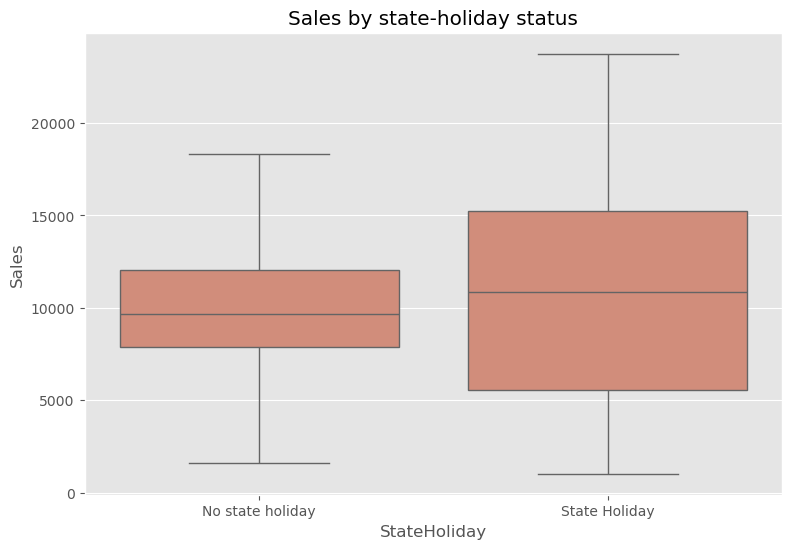

In [5]:
plt.figure(figsize=(9,6))
sns.boxplot(data=df,x='StateHoliday',y='Sales',order=[0,1],showfliers=False,color='#df856d')
plt.xticks([0,1],['No state holiday','State Holiday'])
plt.title('Sales by state-holiday status')
plt.xlabel('StateHoliday'); plt.ylabel('Sales')
display(df.groupby('StateHoliday').Sales.agg(['size','mean','median']))

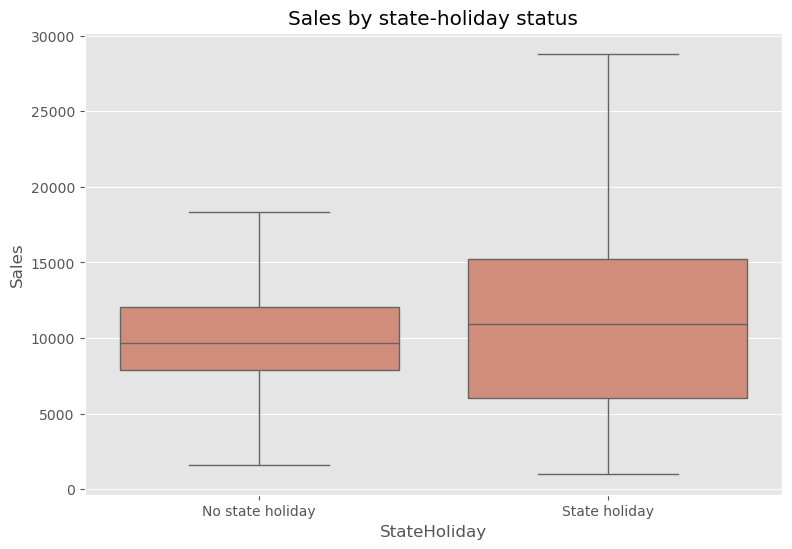

,size,mean,median
HolidayStatus,,,
0,174562,10406.252203,9686.0
1,438,11603.630137,10922.5


In [6]:
df["HolidayStatus"] = df["StateHoliday"].apply(
    lambda x: 0 if x == 0 or x == "0" else 1
)

plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x="HolidayStatus",
    y="Sales",
    order=[0,1],
    showfliers=False,
    color="#df856d"
)

plt.xticks([0,1], ["No state holiday", "State holiday"])
plt.title("Sales by state-holiday status")
plt.xlabel("StateHoliday")
plt.ylabel("Sales")

plt.show()

display(df.groupby("HolidayStatus").Sales.agg(
    ["size", "mean", "median"]
))